# 02 — Forward model of the observables: Voigt-fitted $N_{HI}$ and temperature

Notebook 01 predicted the column density the *pipeline* stores. This one predicts what an
*observer* would measure: a single-component Voigt profile is fitted to every HCD spectrum,
and the two fitted parameters become the targets of a neural network,

$$(\log M_{200},\ c_{200},\ b) \;\longrightarrow\; \bigl(\log N_{HI}^{\rm fit},\ \log T^{\rm fit}\bigr).$$

### Why fit, instead of using the stored `temp`?

The per-pixel `temp` column is simulation truth that no observer ever sees. What a survey
measures is a *line width*, converted to a temperature through the Doppler relation
$b = \sqrt{2kT/m_H}$. Fitting the mock spectra puts the targets in observer space — which is
the space where a model like this gets used.

Two physical consequences to keep in mind while reading every plot below:

* **The fitted $T$ is an effective line-width temperature.** A single Voigt cannot separate
  thermal broadening from the velocity structure of the gas along the sightline, so
  $T^{\rm fit}$ is thermal $\oplus$ kinematics. Expect it to sit *above* the simulation's
  HI-weighted temperature — Section 6 measures by how much.
* **The two targets are constrained in opposite regimes** (the curve of growth). An LLS-range
  line is saturated but has no damping wings: the *width* of its trough measures $b$ well,
  while $N$ sits on the flat part and is poorly constrained. A DLA has damping wings that pin
  $N$ precisely — but the wings are independent of $b$ and the core is black, so $T$ is barely
  constrained. On top of that, the 10 km/s pixels cannot resolve $b \lesssim 10$ km/s, i.e.
  $T^{\rm fit} \lesssim 6000$ K sits at the resolution floor.

So neither target is good everywhere; they trade places. That is not a flaw of the method —
it is what the observable actually contains, and the per-regime table in Section 9 makes it
explicit.

Part 1 of notebook 01 — the covering fraction — is unchanged and not repeated here. This
notebook lives on the sightlines above the $10^{17.2}$ cut, where there is a line to fit.

Place it in `FakeSpectra_DLAs/training/`.

---
## Extra packages

The same three as notebook 01 — nothing new:

```bash
conda activate fakespectra
pip install scikit-learn lightgbm ipympl
```

The Voigt function comes from `scipy.special.wofz`, the parallel fitting from `joblib`
(installed together with scikit-learn), and the network is scikit-learn's `MLPRegressor`.
`torch` is still not needed.

In [2]:
import numpy as np

In [3]:
import importlib

for _name in ["numpy", "pandas", "scipy", "matplotlib", "sklearn", "lightgbm",
              "joblib", "tqdm"]:
    try:
        _m = importlib.import_module(_name)
        print(f"{_name:<12} {getattr(_m, '__version__', '?')}")
    except ImportError:
        print(f"{_name:<12} *** MISSING -- pip install it before continuing ***")

numpy        1.26.4
pandas       2.3.3
scipy        1.17.0
matplotlib   3.10.8
sklearn      1.9.0
lightgbm     4.7.0
joblib       1.5.3
tqdm         4.67.1


---
## 1. Setup

In [4]:
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path("..").resolve()                     # this notebook lives in training/
DATA_DIR  = REPO_ROOT / "data_TNG50-2_snap025_5runs"

HUBBLE_H = 0.6774          # TNG cosmology; h is not stored in df.attrs
TEST_FRACTION = 0.25       # fraction of HALOES held out, not of rows
SEED = 42

sys.path.append(str(REPO_ROOT / "tools"))
import radii_skewers as rs

In [5]:
def matplotlib_default_config():
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 20, "axes.labelsize" : 20,
        "legend.fontsize" : 12, 'legend.fancybox': True, 'lines.linewidth': 2.5,
        'xtick.direction': 'in', 'ytick.direction': 'in',
        'xtick.top': True, 'ytick.right': True,
        'xtick.labelsize': 18, 'ytick.labelsize': 18
    }
    return font, rcnew

%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
plt.close('all')

---
## 2. Loading

Unlike notebook 01 the arrays are the whole point here, so one pickle is read whole: `flux`
feeds the Voigt fit, and `temp`/`n_hi_col` give the simulation's HI-weighted temperature for
the comparison in Section 6. One realization is enough — the fit is the expensive step, and
five runs would quintuple it for haloes that largely repeat at the massive end.

In [11]:
FILE = sorted(DATA_DIR.glob("*.pkl"))[0]
print("reading", FILE.name, "...")

df = pd.read_pickle(FILE)
meta = dict(df.attrs)
V = np.asarray(meta["v_grid"], dtype=float)          # km/s, shared by every spectrum

print(f"{len(df):,} sightlines | {df.halo_id.nunique():,} haloes | "
      f"{df.is_hcd.mean():.1%} above the {meta['hcd_log_nhi_cut']} cut")
print(f"velocity grid: {meta['nbins']} pixels of {meta['dvbin']:.0f} km/s "
      f"({V.min():.0f} to {V.max():.0f} km/s)")

reading TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl ...
231,231 sightlines | 637 haloes | 49.5% above the 17.2 cut
velocity grid: 396 pixels of 10 km/s (-1981 to 1981 km/s)


---
## 3. The Voigt profile

A single Ly$\alpha$ line in velocity space. The optical depth is

$$\tau(v) \;=\; N_{HI}\,\frac{\sqrt{\pi}\,e^2}{m_e c}\,\frac{f\,\lambda_0}{b}\; H(a,\,x),
\qquad x = \frac{v - v_0}{b}, \qquad a = \frac{\Gamma\,\lambda_0}{4\pi\,b},$$

with $H(a,x) = \mathrm{Re}\,[w(x+ia)]$ the Voigt–Hjerting function (`scipy.special.wofz`),
$f = 0.4164$ the oscillator strength, $\Gamma = 6.265\times10^8\,\mathrm{s^{-1}}$ the damping
constant, and $b = \sqrt{2kT/m_H}$ turning the fitted width into a temperature. The
transmitted flux is $F = e^{-\tau}$.

The constants are folded into two numbers below, and the cell checks itself against the
textbook benchmark: $\tau_0 \approx 0.76$ for $N_{HI} = 10^{13}\,\mathrm{cm^{-2}}$ at
$b = 10$ km/s.

In [12]:
from scipy import special as sp_special      # NOT "from scipy.special import wofz"

TAU_COEF = 7.580e-13
A_COEF   = 6.061e-3
B_COEF   = 0.12798

def voigt_flux(v, log_n, v0, log_T):
    """Transmitted flux F = exp(-tau) of one Lya line at velocity grid v [km/s]."""
    b = B_COEF * np.sqrt(10.0 ** log_T)              # Doppler parameter [km/s]
    x = (v - v0) / b
    H = sp_special.wofz(x + 1j * (A_COEF / b)).real  # Voigt-Hjerting function
    return np.exp(-(10.0 ** log_n) * TAU_COEF / b * H)

_T10 = np.log10((10.0 / B_COEF) ** 2)
_tau0 = -np.log(voigt_flux(np.array([0.0]), 13.0, 0.0, _T10))[0]
print(f"tau_0 benchmark: {_tau0:.3f}   (textbook value ~0.76)")

tau_0 benchmark: 0.757   (textbook value ~0.76)


---
## 4. The fitter

Three free parameters: $(\log N_{HI},\ v_0,\ \log T)$. The temperature is fitted in log
because it spans four decades — a linear parameter with those bounds gives `curve_fit` steps
that are meaningless at the low end.

Two details that make the fit robust:

* **Two starting points**, one LLS-like ($\log N = 18.5$) and one DLA-like ($\log N = 20.6$),
  keeping whichever converges to the smaller squared error. The curve of growth makes the
  $\chi^2$ surface bimodal-ish in $N$ for saturated lines, and a single start regularly
  falls into the wrong branch.
* **$v_0$ initialised from `vel_peak_shift`** — the velocity of the deepest trough, which
  the pipeline already computed from this same flux. That is data an observer also has, so
  using it does not leak anything.

A fit is flagged bad when `curve_fit` fails on both starts or when a parameter lands on a
bound (a pinned parameter is the optimiser saying "outside my box", not a measurement).

In [13]:
from scipy.optimize import curve_fit

BOUNDS = ([13.0, -1500.0, 2.0], [24.0, 1500.0, 7.5])     # log_n, v0, log_T
STARTS_LOGN = (18.5, 20.6)                                # LLS-like and DLA-like

def fit_voigt(flux, v_grid, v0_init):
    """Two-start least-squares Voigt fit of one spectrum.

    Returns (log_n, v0, log_T, sse); NaNs when both starts fail."""
    v0_init = float(np.clip(v0_init, -1400.0, 1400.0))
    best = None
    for n0 in STARTS_LOGN:
        try:
            popt, _ = curve_fit(voigt_flux, v_grid, flux,
                                p0=[n0, v0_init, 4.3], bounds=BOUNDS, maxfev=4000)
        except RuntimeError:                              # no convergence from this start
            continue
        sse = float(np.sum((voigt_flux(v_grid, *popt) - flux) ** 2))
        if best is None or sse < best[3]:
            best = (*popt, sse)
    return best if best is not None else (np.nan,) * 4

---
## 5. Fitting every HCD spectrum

Roughly 5–15 minutes on the 20-core machine for the ~100k HCD spectra of one realization.
The results are cached, so the cell is slow exactly once — delete the cache file to force a
refit.

The cell also breaks the bad fits down by parameter and by class, because the two failure
modes mean different things. A fit pinned at the **lower $T$ bound** is the damped-core
degeneracy in action: the core is black, the wings do not depend on $b$, so nothing in the
spectrum holds the temperature up and the optimiser slides to the box. Expect that column to
concentrate in the DLA classes — and note that dropping those rows thins the sample exactly
at the damped end, which is worth keeping in mind when reading every result downstream.

In [14]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm

hcd = df[df.is_hcd].copy()
hcd.attrs = {}                       # the attrs hold arrays and only get in the way here

Path("cache").mkdir(exist_ok=True)
cache_file = Path("cache") / f"voigt_fits_{FILE.stem}.pkl"

if cache_file.exists():
    fits = pd.read_pickle(cache_file)
    assert fits.index.equals(hcd.index), "cache does not match this file -- delete it"
    print(f"cache: {cache_file.name} ({len(fits):,} fits)")
else:
    tasks = (delayed(fit_voigt)(np.asarray(f, dtype=float), V, v0)
             for f, v0 in zip(hcd["flux"], hcd["vel_peak_shift"]))
    res = Parallel(n_jobs=-1, batch_size=128)(tqdm(tasks, total=len(hcd)))
    fits = pd.DataFrame(res, columns=["fit_log_nhi", "fit_v0", "fit_logT", "fit_sse"],
                        index=hcd.index)
    fits.to_pickle(cache_file)
    print("cached ->", cache_file)

hcd = hcd.join(fits)

# A parameter within eps of a bound was not measured, it was stopped by the box.
eps = 0.03
pin_N = ((np.abs(hcd.fit_log_nhi - BOUNDS[0][0]) < eps)
         | (np.abs(hcd.fit_log_nhi - BOUNDS[1][0]) < eps))
pin_T = ((np.abs(hcd.fit_logT - BOUNDS[0][2]) < eps)
         | (np.abs(hcd.fit_logT - BOUNDS[1][2]) < eps))

hcd["fit_ok"] = np.isfinite(hcd["fit_log_nhi"]) & ~pin_N & ~pin_T
print(f"\nfailed (no convergence) : {(~np.isfinite(hcd.fit_log_nhi)).mean():.2%}")
print(f"pinned in log N         : {pin_N.mean():.2%}")
print(f"pinned in log T         : {pin_T.mean():.2%}")
print(f"usable fits             : {hcd.fit_ok.sum():,} / {len(hcd):,}")

# Where does the T-pinning live? If the intro's physics is right, in the damped classes.
tab = pd.crosstab(rs.categorize(hcd["log_n_hi"]), pin_T, normalize="index")
if True in tab.columns:
    print("\nfraction with T pinned, by class:")
    print(tab[True].round(3).to_string())

  0%|          | 0/114350 [00:00<?, ?it/s]

cached -> cache/voigt_fits_TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl

failed (no convergence) : 0.00%
pinned in log N         : 0.00%
pinned in log T         : 12.05%
usable fits             : 100,566 / 114,350

fraction with T pinned, by class:
log_n_hi
LLS          0.005
Sub_DLA      0.002
Small_DLA    0.125
Large_DLA    0.834


---
## 6. Does the fit make sense?

Three checks before trusting the targets.

**Examples.** One spectrum per absorber class with the fitted profile on top.

**$N$ against the stored column.** The stored `log_n_hi` is the pipeline's exact integral, so
this comparison *is* the curve of growth: tight along the diagonal for DLAs (the damping
wings pin $N$), a broad cloud in the LLS range (the flat part — $N$ is genuinely degenerate
there, and that scatter is a property of the observable, not a bug of the fitter).

**$T$ against the simulation.** The fitted line-width temperature against the HI-weighted
`temp` of the same sightline. Points should sit *on or above* the diagonal: kinematic
broadening only ever adds width.

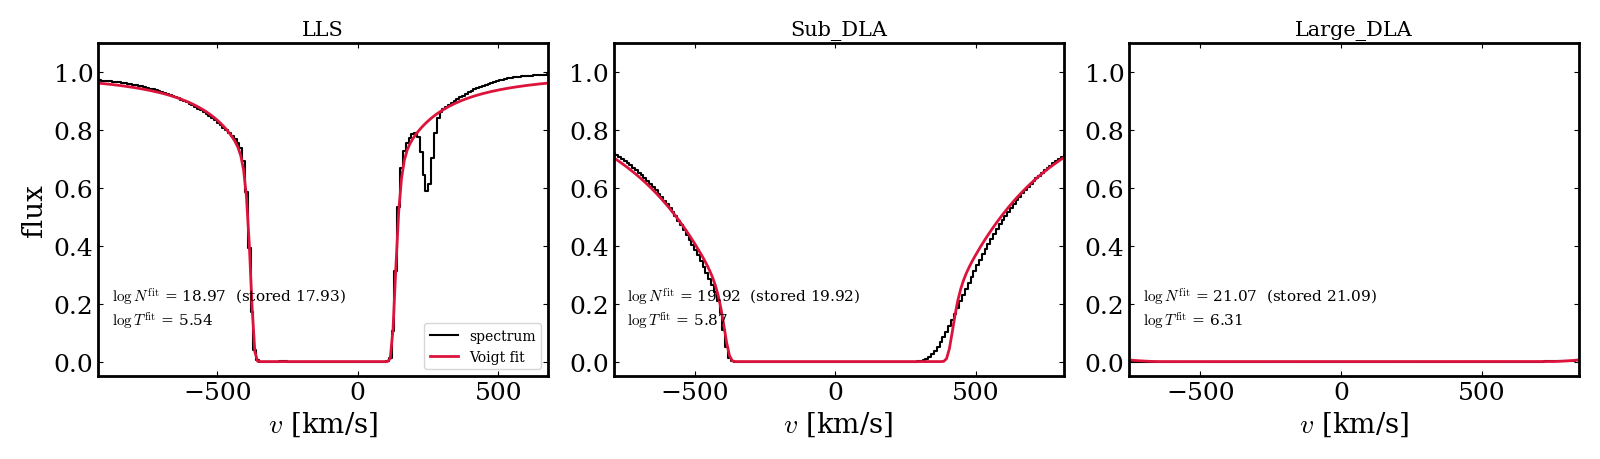

In [15]:
hcd["category"] = rs.categorize(hcd["log_n_hi"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, cls in zip(axes, ["LLS", "Sub_DLA", "Large_DLA"]):
    sel = hcd[(hcd.category == cls) & hcd.fit_ok]
    if sel.empty:
        continue
    row = sel.iloc[0]
    ax.plot(V, np.asarray(row["flux"], dtype=float), color="k", lw=1.5,
            drawstyle="steps-mid", label="spectrum")
    ax.plot(V, voigt_flux(V, row.fit_log_nhi, row.fit_v0, row.fit_logT),
            color="crimson", lw=2, label="Voigt fit")
    ax.set_xlim(row.fit_v0 - 800, row.fit_v0 + 800)
    ax.set_ylim(-0.05, 1.1)
    ax.set_xlabel(r"$v$ [km/s]")
    ax.set_title(cls, fontsize=15)
    ax.text(0.03, 0.15,
            (fr"$\log N^{{\rm fit}}$ = {row.fit_log_nhi:.2f}  (stored {row.log_n_hi:.2f})"
             "\n" fr"$\log T^{{\rm fit}}$ = {row.fit_logT:.2f}"),
            transform=ax.transAxes, fontsize=11)
axes[0].set_ylabel("flux")
axes[0].legend(fontsize=10, loc="lower right")
fig.tight_layout()
plt.show()

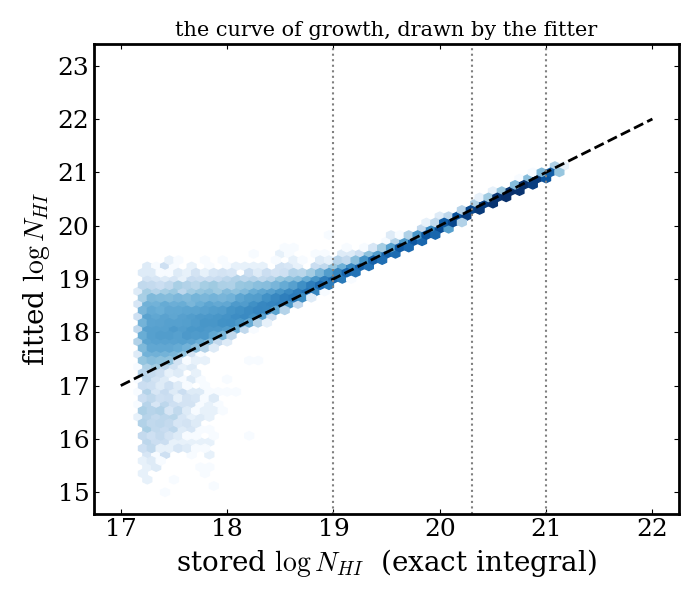

LLS        fit - stored: median +0.22  scatter 0.39 dex   (23,485 fits)
Sub_DLA    fit - stored: median -0.06  scatter 0.03 dex   (28,492 fits)
Small_DLA  fit - stored: median -0.06  scatter 0.01 dex   (47,214 fits)
Large_DLA  fit - stored: median -0.06  scatter 0.01 dex   (1,375 fits)


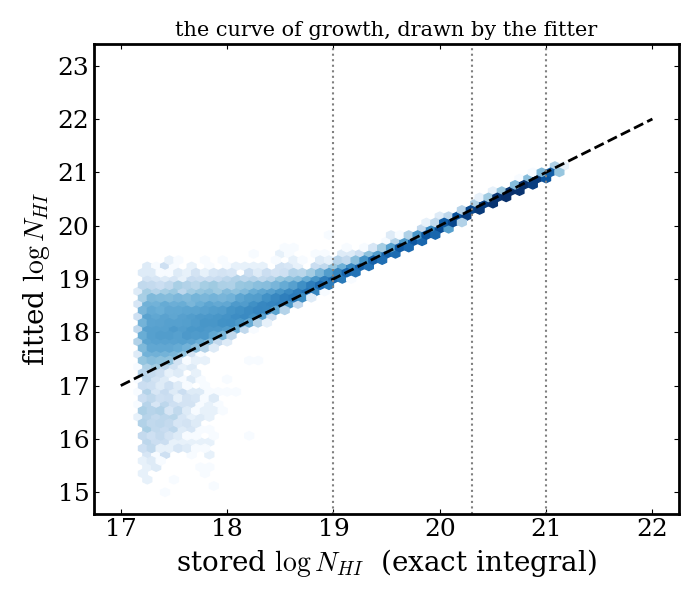

In [16]:
ok = hcd[hcd.fit_ok]

fig, ax = plt.subplots(figsize=(7, 6))
ax.hexbin(ok["log_n_hi"], ok["fit_log_nhi"], gridsize=60, bins="log", cmap="Blues",
          extent=(17, 22, 15, 23))
ax.plot([17, 22], [17, 22], "k--", lw=2)
for e in (19.0, 20.3, 21.0):                       # the class edges
    ax.axvline(e, color="grey", ls=":", lw=1.5)
ax.set_xlabel(r"stored $\log N_{HI}$  (exact integral)")
ax.set_ylabel(r"fitted $\log N_{HI}$")
ax.set_title("the curve of growth, drawn by the fitter", fontsize=15)
fig.tight_layout()
plt.show()

for cls in rs.CATEGORY_LABELS[1:]:
    sub = ok[ok.category == cls]
    if len(sub):
        d = sub["fit_log_nhi"] - sub["log_n_hi"]
        print(f"{cls:<10} fit - stored: median {d.median():+.2f}  scatter {d.std():.2f} dex"
              f"   ({len(sub):,} fits)")
plt.show()

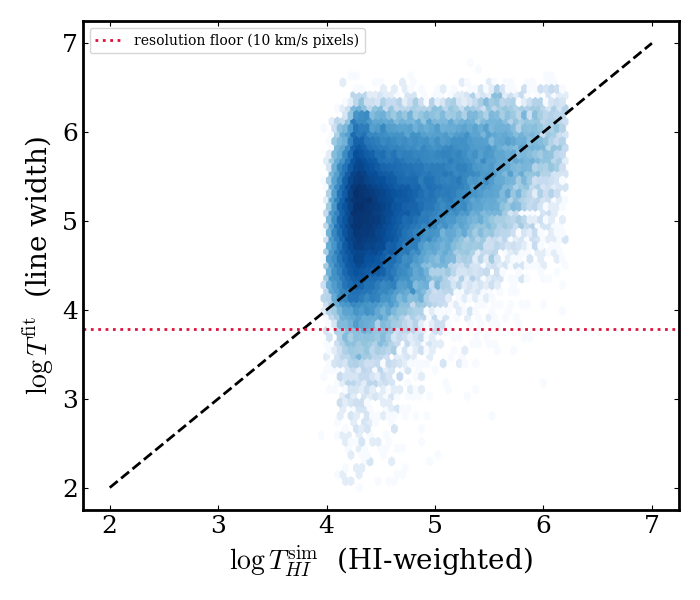

fit - sim: median +0.56 dex  ->  the kinematic-broadening excess


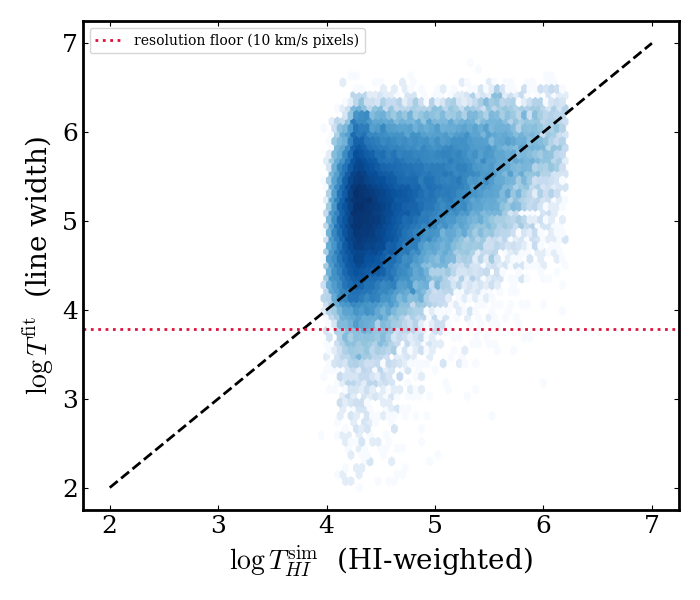

In [17]:
# The simulation's own answer for the same sightline: the N_HI-weighted temperature,
# recomputed from the stored per-pixel arrays.
ok = ok.copy()
ok["T_hi_sim"] = [rs.hi_weighted_temperature(t, n)
                  for t, n in zip(ok["temp"], ok["n_hi_col"])]

sel = ok[ok["T_hi_sim"] > 0]
fig, ax = plt.subplots(figsize=(7, 6))
ax.hexbin(np.log10(sel["T_hi_sim"]), sel["fit_logT"], gridsize=60, bins="log",
          cmap="Blues", extent=(3.2, 6.2, 2, 7))
ax.plot([2, 7], [2, 7], "k--", lw=2)
ax.axhline(np.log10((meta["dvbin"] / B_COEF) ** 2), color="crimson", ls=":", lw=2,
           label=f"resolution floor ({meta['dvbin']:.0f} km/s pixels)")
ax.set_xlabel(r"$\log T_{HI}^{\rm sim}$  (HI-weighted)")
ax.set_ylabel(r"$\log T^{\rm fit}$  (line width)")
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()

d = sel["fit_logT"] - np.log10(sel["T_hi_sim"])
print(f"fit - sim: median {d.median():+.2f} dex  ->  the kinematic-broadening excess")

# the arrays have done their job; free the ~1 GB before training anything
hcd = hcd.drop(columns=["flux", "n_hi_col", "temp"])
del df, ok, sel
plt.show()

---
## 7. Features and split

The four physical features of notebook 01. The two null-test codes (`axis`, `pos_code`) stay
out here: the null test already lives in 01, and an MLP — unlike LightGBM — offers no free
importance readout to monitor them with.

One practical difference: `MLPRegressor` cannot digest NaN, so the undefined $c_{200}$ values
(the $V_{max}/V_{200} \le 1$ tail) are median-imputed *inside* the pipeline — the median is
learned on the training folds only, so nothing leaks.

The split is by halo, exactly as before.

In [18]:
from sklearn.model_selection import GroupShuffleSplit

rs.add_concentration(hcd, meta)
a_scale = 1.0 / (1.0 + float(meta["redshift"]))

hcd["log_M200"]   = np.log10(hcd["halo_mass"] * 1e10 / HUBBLE_H)
hcd["log_b_r200"] = np.log10(hcd["r_multiplier"] + 0.005)
hcd["log_b_kpc"]  = np.log10(hcd["impact_kpc"] * a_scale / HUBBLE_H + 0.01)

FEATURES = ["log_M200", "halo_c200", "log_b_r200", "log_b_kpc"]
TARGETS  = ["fit_log_nhi", "fit_logT"]

data = hcd[hcd.fit_ok].copy()

gss = GroupShuffleSplit(n_splits=1, test_size=TEST_FRACTION, random_state=SEED)
i_tr, i_te = next(gss.split(data, groups=data["halo_id"]))
train, test = data.iloc[i_tr].copy(), data.iloc[i_te].copy()

assert not (set(train.halo_id) & set(test.halo_id)), "leakage: a halo is on both sides"
print(f"train  {len(train):>7,} rows  {train.halo_id.nunique():>4} haloes")
print(f"test   {len(test):>7,} rows  {test.halo_id.nunique():>4} haloes")

train   75,076 rows   477 haloes
test    25,490 rows   160 haloes


---
## 8. The network

A small MLP, `4 -> 64 -> 64 -> 2`, predicting the two targets **jointly**. The joint output
is the reason to use a network at all here: the two quantities share one physical cause (the
line profile), and a shared trunk can exploit that, whereas two separate regressors cannot.

Both inputs and outputs are standardized — the outputs through `TransformedTargetRegressor`,
so the MSE weighs the two targets equally instead of letting the wider one dominate. One
honest caveat: `early_stopping` carves its validation split by *row*, not by halo, so the
stopping epoch is chosen with slightly optimistic feedback. The test metrics are unaffected
— those haloes were never seen.

In [19]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor

nn = TransformedTargetRegressor(
    regressor=make_pipeline(
        SimpleImputer(strategy="median"),          # the NaN c200 tail
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(64, 64), activation="relu",
                     max_iter=500, early_stopping=True, n_iter_no_change=20,
                     validation_fraction=0.1, random_state=SEED),
    ),
    transformer=StandardScaler(),
)

nn.fit(train[FEATURES], train[TARGETS])
pred = nn.predict(test[FEATURES])

mlp = nn.regressor_.named_steps["mlpregressor"]
print(f"stopped after {mlp.n_iter_} epochs "
      f"(best validation score {mlp.best_validation_score_:.4f})")

stopped after 119 epochs (best validation score 0.5391)


---
## 9. How well — and *where* — it predicts

Global numbers first, then the table that carries the physics: the same metrics split by
absorber class. The intro said the two targets trade places along the curve of growth — if
that is right, the $N$ residual should shrink with class (best for `Large_DLA`) while the $T$
residual should be smallest for `LLS`, where the trough width actually measures $b$. Part of
each residual is the *fit's* noise, not the network's: in the degenerate regimes no feature
set can predict a quantity the spectrum itself does not pin down.

In [20]:
res = pd.DataFrame(test[TARGETS].to_numpy() - pred,
                   columns=["dN", "dT"], index=test.index)

print(f"{'target':<14}{'MAE':>8}{'RMS':>8}   [dex]")
for col, t in zip(["dN", "dT"], TARGETS):
    print(f"{t:<14}{res[col].abs().mean():>8.3f}{np.sqrt((res[col]**2).mean()):>8.3f}")

per_class = (res.abs()
             .join(test["category"])
             .groupby("category", observed=True)
             .agg(MAE_N=("dN", "mean"), MAE_T=("dT", "mean"), n=("dN", "size")))
print("\nMAE by absorber class [dex]:")
print(per_class.round(3).to_string())

target             MAE     RMS   [dex]
fit_log_nhi      0.425   0.576
fit_logT         0.281   0.382

MAE by absorber class [dex]:
           MAE_N  MAE_T      n
category                      
LLS        0.649  0.196   5968
Sub_DLA    0.462  0.244   7241
Small_DLA  0.289  0.337  11938
Large_DLA  0.471  0.631    343


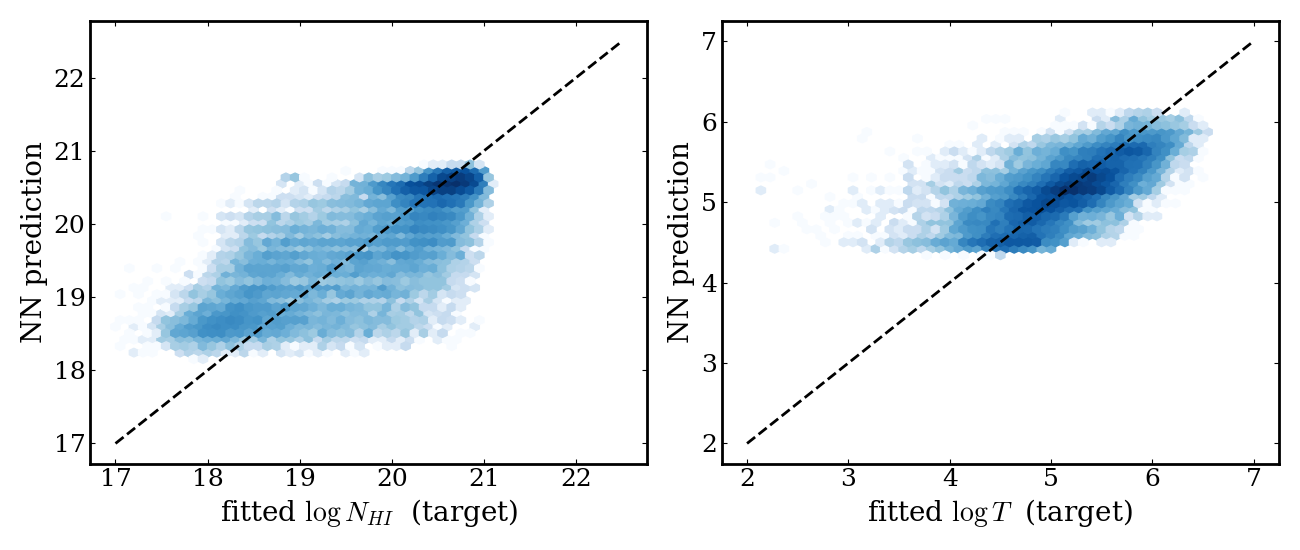

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].hexbin(test["fit_log_nhi"], pred[:, 0], gridsize=55, bins="log", cmap="Blues",
               extent=(17, 22.5, 17, 22.5))
axes[0].plot([17, 22.5], [17, 22.5], "k--", lw=2)
axes[0].set_xlabel(r"fitted $\log N_{HI}$  (target)")
axes[0].set_ylabel(r"NN prediction")

axes[1].hexbin(test["fit_logT"], pred[:, 1], gridsize=55, bins="log", cmap="Blues",
               extent=(2, 7, 2, 7))
axes[1].plot([2, 7], [2, 7], "k--", lw=2)
axes[1].set_xlabel(r"fitted $\log T$  (target)")
axes[1].set_ylabel(r"NN prediction")

fig.tight_layout()
plt.show()

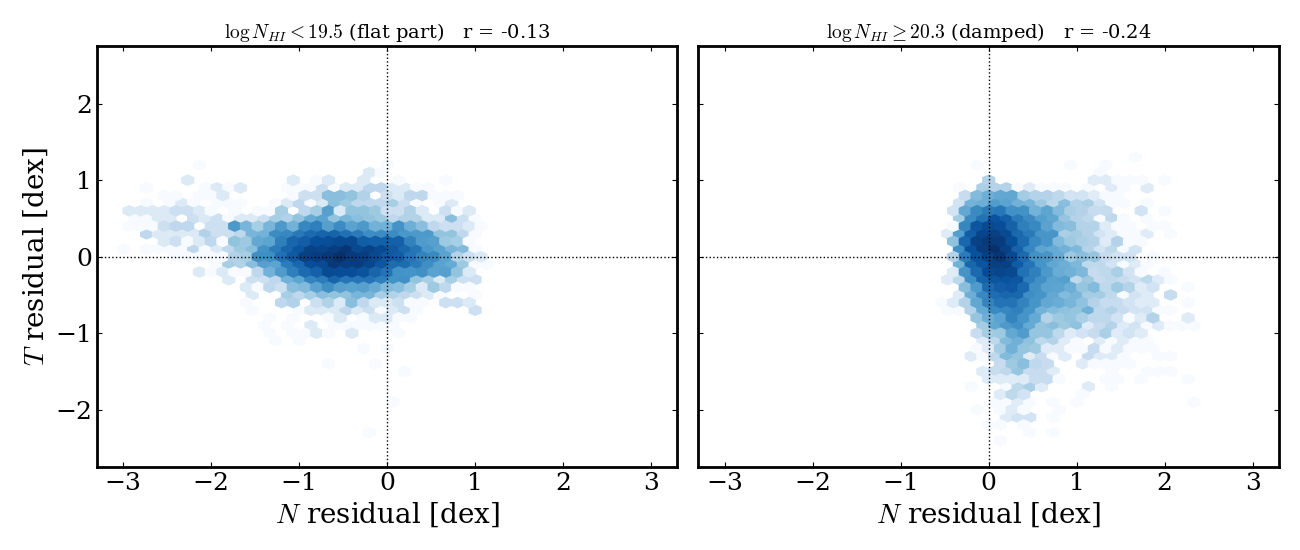

In [22]:
# The curve-of-growth degeneracy, seen from the residual side: on the flat part the
# fitter trades N for b, so where the fit is degenerate the two errors should be
# anti-correlated. Damped systems pin N independently of b, so there they should not.
lls = res[test["log_n_hi"] < 19.5]
dla = res[test["log_n_hi"] >= 20.3]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, sub, name in [(axes[0], lls, r"$\log N_{HI} < 19.5$ (flat part)"),
                      (axes[1], dla, r"$\log N_{HI} \geq 20.3$ (damped)")]:
    ax.hexbin(sub["dN"], sub["dT"], gridsize=45, bins="log", cmap="Blues",
              extent=(-3, 3, -2.5, 2.5))
    ax.axhline(0, color="k", lw=1, ls=":")
    ax.axvline(0, color="k", lw=1, ls=":")
    r_corr = sub["dN"].corr(sub["dT"])
    ax.set_title(f"{name}   r = {r_corr:+.2f}", fontsize=14)
    ax.set_xlabel(r"$N$ residual [dex]")
axes[0].set_ylabel(r"$T$ residual [dex]")
fig.tight_layout()
plt.show()

---
## 10. Sanity reference: two independent gradient boosters

Is the joint network at least as good as the obvious alternative — one LightGBM per target,
no sharing? If the MLP loses badly, the architecture is hurting; if it matches, the joint
model is fine and comes with the shared trunk that a density head can be attached to later.

In [23]:
import lightgbm as lgb

print(f"{'target':<14}{'NN MAE':>9}{'LGBM MAE':>10}   [dex]")
for j, t in enumerate(TARGETS):
    g = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63,
                          min_child_samples=100, random_state=SEED,
                          n_jobs=-1, verbose=-1)
    g.fit(train[FEATURES], train[t])                 # LightGBM eats the NaN c200 natively
    mae_g = np.abs(test[t] - g.predict(test[FEATURES])).mean()
    mae_n = res[["dN", "dT"][j]].abs().mean()
    print(f"{t:<14}{mae_n:>9.3f}{mae_g:>10.3f}")

target           NN MAE  LGBM MAE   [dex]
fit_log_nhi       0.425     0.435
fit_logT          0.281     0.290


---
## 11. Save

In [24]:
Path("models").mkdir(exist_ok=True)
with open("models/forward_voigt_nn_v0.pkl", "wb") as fh:
    pickle.dump({"model": nn, "FEATURES": FEATURES, "TARGETS": TARGETS,
                 "voigt_bounds": BOUNDS, "hubble_h": HUBBLE_H,
                 "redshift": float(meta["redshift"]), "source_file": FILE.name}, fh)
print("saved -> models/forward_voigt_nn_v0.pkl")

saved -> models/forward_voigt_nn_v0.pkl


---
## Where to go next

1. **A density head.** Swap the two-number output for a Mixture Density Network over the
   joint $(\log N,\ \log T)$ — the residual plots above show the spread and the class-dependent
   degeneracy that a point prediction cannot carry.
2. **Orientation.** The same feature that notebook 01 flagged: the gap to the irreducible
   floor is the budget, and the line-width target is even more orientation-sensitive than the
   column.
3. **A masked loss.** The rows dropped for pinned $T$ still carry an excellent $N$
   measurement — a two-headed network with a per-target mask (straightforward in `torch`,
   not in scikit-learn) would keep them instead of thinning the DLA end.
4. **Fit-noise floor.** The 12 sightlines per $(halo, b)$ give the irreducible scatter of the
   *fitted* quantities too — the direct analogue of notebook 01's Section 8, now in observer
   space.
5. **Close the loop.** Covering fraction (01, Part 1) + this network = a complete emulator of
   what a survey would see around a halo: sample $b$, flip the coin, read off
   $(N^{\rm fit}, T^{\rm fit})$.